In [1]:
from google.colab import files

uploaded = files.upload()

Saving IBM_HR_Attrition.csv.csv to IBM_HR_Attrition.csv.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("IBM_HR_Attrition.csv.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("MISSING VALUES")
print(df.isnull().sum().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nTARGET DISTRIBUTION")
print(df["Attrition"].value_counts())

MISSING VALUES
0

DUPLICATE ROWS
0

TARGET DISTRIBUTION
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [4]:
df = df.drop(
    columns=[
        "EmployeeCount",
        "EmployeeNumber",
        "Over18",
        "StandardHours"
    ]
)

df["Attrition"] = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

print("Unnecessary Columns Removed!")
print("Target Encoding Completed!")
print("New Dataset Shape:", df.shape)

display(df.head())

Unnecessary Columns Removed!
Target Encoding Completed!
New Dataset Shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (1176, 30)
Testing Data: (294, 30)

Training Target Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Target Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [6]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("NUMERICAL COLUMNS:", len(numerical_cols))
print(numerical_cols)

print("\nCATEGORICAL COLUMNS:", len(categorical_cols))
print(categorical_cols)

NUMERICAL COLUMNS: 23
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

CATEGORICAL COLUMNS: 7
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [8]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed Successfully!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Preprocessing Completed Successfully!
Processed Training Shape: (1176, 51)
Processed Testing Shape: (294, 51)


In [9]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, class_weights_array)
)

print("CLASS WEIGHTS")
print(class_weights)

CLASS WEIGHTS
{np.int64(0): np.float64(0.5963488843813387), np.int64(1): np.float64(3.094736842105263)}


In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

tf.random.set_seed(42)

ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6798 - auc: 0.5407 - loss: 0.7352 - precision: 0.1814 - recall: 0.2867 - val_accuracy: 0.6102 - val_auc: 0.6642 - val_loss: 0.6577 - val_precision: 0.2500 - val_recall: 0.6500
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5979 - auc: 0.6373 - loss: 0.6619 - precision: 0.2192 - recall: 0.5933 - val_accuracy: 0.5890 - val_auc: 0.7261 - val_loss: 0.6592 - val_precision: 0.2522 - val_recall: 0.7250
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6287 - auc: 0.7147 - loss: 0.6077 - precision: 0.2531 - recall: 0.6800 - val_accuracy: 0.6483 - val_auc: 0.7637 - val_loss: 0.6094 - val_precision: 0.2784 - val_recall: 0.6750
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7043 - auc: 0.7583 - loss: 0.5854 - precision: 0.3084 - recall: 0.6867 - val_accuracy: 0.6992 - val_auc: 0.7906 - val_loss: 0.5774 - val_precision: 0.3218 - val_recall: 0.7000
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━

In [12]:
test_results = ann_model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

print("INTEGRATED ANN TEST RESULTS")

for name, value in zip(ann_model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

INTEGRATED ANN TEST RESULTS
loss: 0.4490
compile_metrics: 0.8095


In [13]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Predict probabilities
y_pred_prob = ann_model.predict(X_test_processed, verbose=0)

# Convert probabilities into 0 or 1
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stay (No)", "Leave (Yes)"]
))

print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_prob))

CONFUSION MATRIX
[[212  35]
 [ 21  26]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Stay (No)       0.91      0.86      0.88       247
 Leave (Yes)       0.43      0.55      0.48        47

    accuracy                           0.81       294
   macro avg       0.67      0.71      0.68       294
weighted avg       0.83      0.81      0.82       294

ROC-AUC Score: 0.7872340425531915


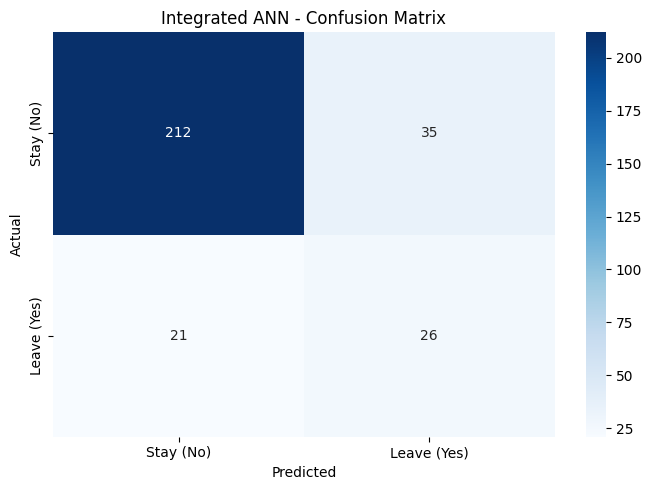

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay (No)", "Leave (Yes)"],
    yticklabels=["Stay (No)", "Leave (Yes)"]
)

plt.title("Integrated ANN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

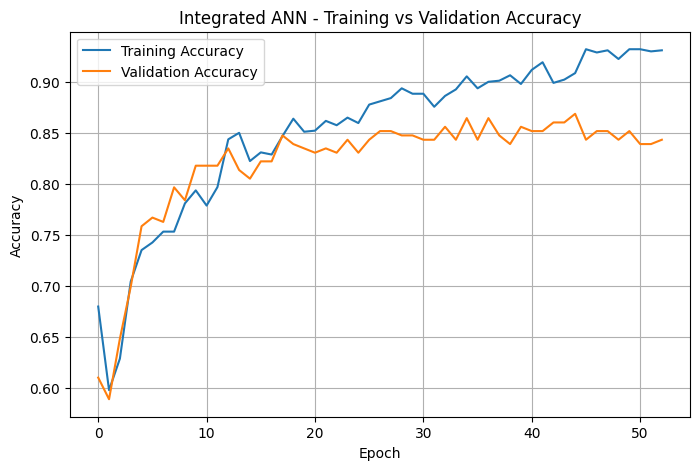

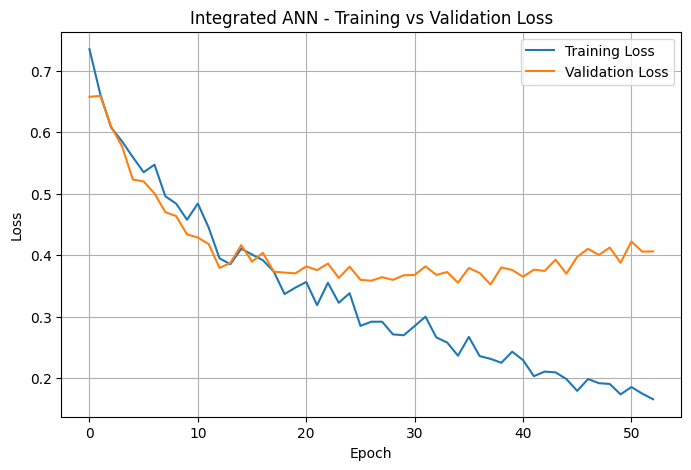

In [15]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Integrated ANN - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Integrated ANN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# Save Integrated ANN Model

ann_model.save("AttriPredict_Integrated_ANN.keras")

print("Integrated ANN Model Saved Successfully!")

Integrated ANN Model Saved Successfully!


In [17]:
import joblib

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "AttriPredict_Integrated_Preprocessor.pkl"
)

print("Integrated Preprocessing Pipeline Saved Successfully!")

Integrated Preprocessing Pipeline Saved Successfully!


In [18]:
# Select one raw employee record
sample_employee = X_test.iloc[[0]]

# Actual employee attrition
actual_result = y_test.iloc[0]

# Apply preprocessing pipeline
sample_processed = preprocessor.transform(sample_employee)

# ANN prediction
prediction_probability = ann_model.predict(
    sample_processed,
    verbose=0
)[0][0]

predicted_result = 1 if prediction_probability >= 0.5 else 0

# Display results
print("INTEGRATED PIPELINE TEST")
print("=" * 40)

print("Actual Result:",
      "Leave (Yes)" if actual_result == 1 else "Stay (No)")

print("Predicted Result:",
      "Leave (Yes)" if predicted_result == 1 else "Stay (No)")

print("Leave Probability:", round(float(prediction_probability) * 100, 2), "%")

print("Prediction:",
      "Correct" if actual_result == predicted_result else "Incorrect")

INTEGRATED PIPELINE TEST
Actual Result: Stay (No)
Predicted Result: Stay (No)
Leave Probability: 24.76 %
Prediction: Correct


In [19]:
from google.colab import files

files.download("AttriPredict_Integrated_ANN.keras")
files.download("AttriPredict_Integrated_Preprocessor.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>